# Homework 9. Классификация и детекция изображений

**Сидоров, РИС-24-1-1.** Все эксперименты выполнены в Python на CPU. Для запуска используйте Python 3.12, установите зависимости из `requirements.txt` и откройте ноутбук из папки работы. Скрипты обучения и веса доступны рядом. Ячейки читают результаты выполненных запусков, а команды в каждом разделе повторяют обучение.

## 1.1. Данные из ДЗ-8

Берём 200 подготовленных кадров с выделенными фигурами. Два класса — человек и гуманоид, по 100 изображений. При фиксированном seed 42 внутри каждого класса выделяем 70/15/15. Файлы сохранены в `dataset/train`, `dataset/validation` и `dataset/test`; внутри — `human` и `humanoid`. Детектор YOLO использует целые сцены B-Human.

In [1]:
import json
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import pandas as pd
from PIL import Image

plt.rcParams["axes.grid"] = False
results = Path("results")

def load(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))

manifest = pd.DataFrame(load("classification_manifest.json"))
counts = pd.crosstab(manifest["split"], manifest["class"]).loc[["train", "validation", "test"]]
display(counts.assign(total=counts.sum(axis=1)))
assert counts.values.tolist() == [[70, 70], [15, 15], [15, 15]]
assert manifest["sha256"].is_unique

class,human,humanoid,total
split,,,
train,70,70,140
validation,15,15,30
test,15,15,30


## 1.2–1.3. Простая CNN и VGG11

Простая CNN состоит из трёх свёрточных блоков. Вторая сеть использует восемь свёрток и пять слоёв max pooling по схеме VGG11. Классификационная голова уменьшена для изображений 64×64 и двух классов. Обе модели обучены с нуля восемь эпох. В каждой лучшая эпоха выбрана по Accuracy на validation с учётом loss при равенстве. Затем выбранные веса проверены на test. Модели и цикл обучения находятся в `classification.py`.

Повторный запуск: `python classification.py`.

,Модель,Лучшая эпоха,Test Accuracy,Test Loss,Верно из 30
0,CNN,3,1.0,0.0071,30
1,VGG11,3,1.0,0.0122,30


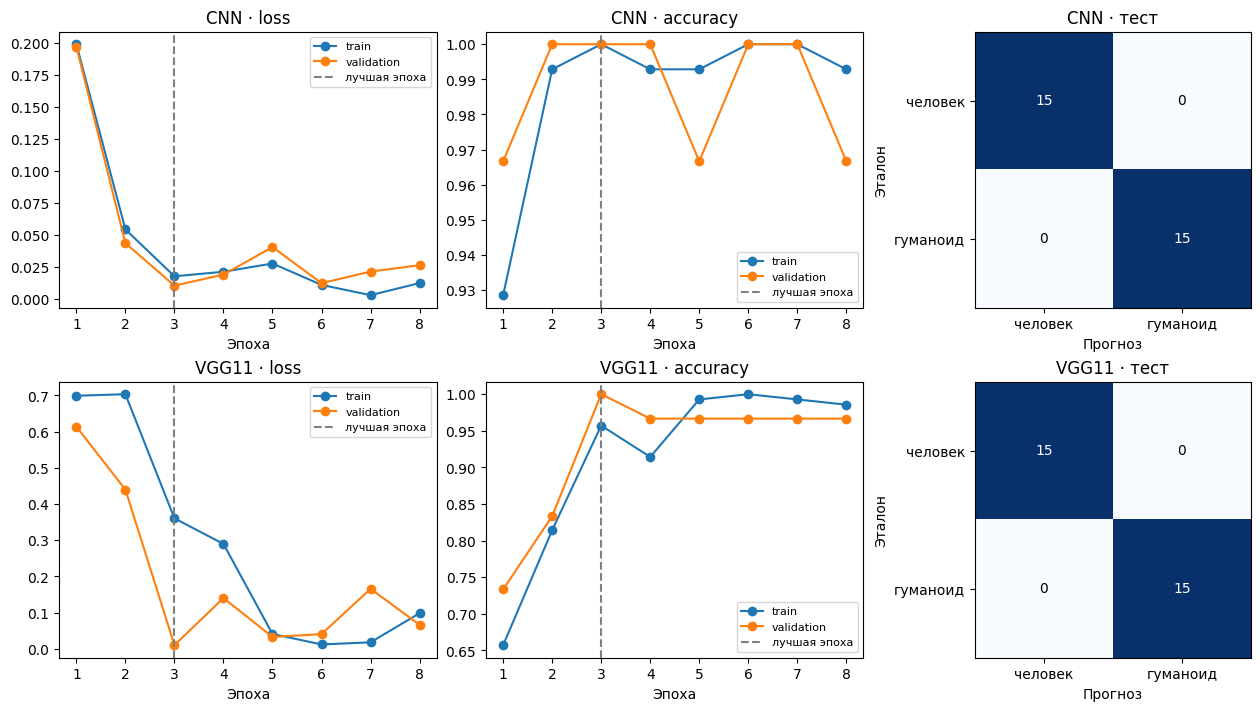

In [2]:
classification = {label: load(results / f"{name}.json") for label, name in [("CNN", "cnn"), ("VGG11", "vgg11")]}
display(pd.DataFrame([
    {"Модель": label, "Лучшая эпоха": run["best_epoch"],
     "Test Accuracy": run["test"]["accuracy"], "Test Loss": run["test"]["loss"],
     "Верно из 30": sum(a == b for a, b in zip(run["test"]["target"], run["test"]["prediction"]))}
    for label, run in classification.items()
]).round(4))

fig, axes = plt.subplots(2, 3, figsize=(13, 7), constrained_layout=True)
for row, (label, run) in zip(axes, classification.items()):
    history = pd.DataFrame(run["history"])
    for axis, metric in zip(row[:2], ["loss", "accuracy"]):
        axis.plot(history.epoch, history[f"train_{metric}"], marker="o", label="train")
        axis.plot(history.epoch, history[f"val_{metric}"], marker="o", label="validation")
        axis.axvline(run["best_epoch"], color="gray", linestyle="--", label="лучшая эпоха")
        axis.set(title=f"{label} · {metric}", xlabel="Эпоха")
        axis.legend(fontsize=8)
    test = run["test"]
    matrix = pd.crosstab(pd.Series(test["target"]), pd.Series(test["prediction"])).reindex([0, 1], axis=0, fill_value=0).reindex([0, 1], axis=1, fill_value=0)
    row[2].imshow(matrix, cmap="Blues", vmin=0, vmax=15)
    for y in range(2):
        for x in range(2):
            value = int(matrix.iloc[y, x])
            row[2].text(x, y, value, ha="center", va="center", color="white" if value > 8 else "black")
    row[2].set(xticks=[0, 1], yticks=[0, 1], xticklabels=["человек", "гуманоид"],
               yticklabels=["человек", "гуманоид"], title=f"{label} · тест", xlabel="Прогноз", ylabel="Эталон")
plt.show()

Обе модели правильно классифицировали 30 из 30 тестовых кадров. На validation CNN достигает 100% уже на второй эпохе, VGG11 — на третьей. Для обеих сетей выбрана третья эпоха. На графиках loss сначала падает, затем validation loss колеблется, особенно у VGG11. Матрицы ошибок показывают 15 верных предсказаний каждого класса у обеих моделей. На этой небольшой выборке преимущества VGG11 по Accuracy нет. Кадры роботов происходят из одного матча и отличаются от фотографий людей по фону и резкости, что ограничивает перенос результата на другие источники.

## 1.4–1.5. Исходная YOLOv8n и выбор класса

Используем веса YOLOv8n, обученные на COCO. Сначала проверяем модель на всех 30 подготовленных тестовых кадрах из ДЗ-8. Новый класс `humanoid_robot` согласован отдельно. В списке COCO такого класса нет. На сценах с роботами исходная модель может выдать другую метку или пропустить объект. Ниже отдельно оцениваются локализация произвольной меткой и правильное присвоение нового класса.

,Класс,Снимки,С хотя бы одной рамкой,Предсказанные метки
0,human,15,15,"{'person': 18, 'bicycle': 4, 'backpack': 2, 'h..."
1,humanoid,15,6,"{'person': 7, 'motorcycle': 1}"


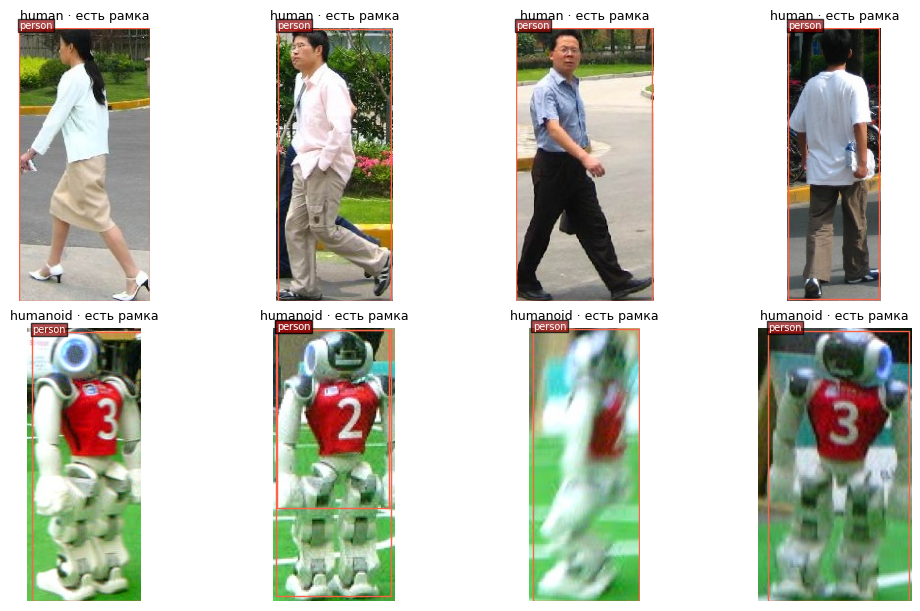

In [3]:
def show_boxes(axis, row, base=Path("."), title=""):
    with Image.open(base / row["scene"]) as photo:
        axis.imshow(photo.convert("RGB"))
    for key, color in [("truth", "lime"), ("boxes", "tomato")]:
        for index, box in enumerate(row.get(key, [])):
            x1, y1, x2, y2 = box
            axis.add_patch(Rectangle((x1, y1), x2-x1, y2-y1, fill=False, edgecolor=color, linewidth=1))
            if key == "boxes" and index < len(row.get("labels", [])):
                axis.text(x1, y1, row["labels"][index], color="white", fontsize=7,
                          bbox={"facecolor": "darkred", "alpha": 0.7, "pad": 1})
    axis.set_title(title, fontsize=9)
    axis.axis("off")

prepared = load(results / "yolo_prepared_classification.json")
display(pd.DataFrame([
    {"Класс": label, "Снимки": len(rows), "С хотя бы одной рамкой": sum(bool(row["boxes"]) for row in rows),
     "Предсказанные метки": dict(Counter(item for row in rows for item in row["labels"]))}
    for label in ["human", "humanoid"] if (rows := [r for r in prepared if r["class"] == label])
]))
fig, axes = plt.subplots(2, 4, figsize=(10, 6), constrained_layout=True)
for axes_row, label in zip(axes, ["human", "humanoid"]):
    chosen = sorted((r for r in prepared if r["class"] == label), key=lambda r: not bool(r["boxes"]))[:4]
    for axis, row in zip(axes_row, chosen):
        show_boxes(axis, row, title=label + (" · есть рамка" if row["boxes"] else " · без рамки"))
plt.show()

В верхнем ряду исходная YOLOv8n выделяет людей с меткой `person`. В нижнем ряду все четыре показанных робота также получили метку `person`. Для графика первыми показаны кадры с найденными рамками, а сводка над ним рассчитана на всех 30 снимках. Это основание добавить новый класс и проверить его на полных сценах.

## 1.6–1.8. Рамки, дообучение и независимый тест YOLOv8

Для одного класса подготовлены 85 сцен train и 15 сцен validation из апрельского матча и 50 целых тестовых сцен из другого матча. Метки в формате YOLO хранят нормированные координаты центра и размеры рамки. На сцене может быть несколько роботов, поэтому используются все рамки источника соответствующего класса, включая упавших роботов. Отложенный матч не используется при обучении.

Исходные рамки B-Human импортированы в приватный проект Roboflow. В редакторе Annotate выборочно сверены четыре кадра из train и validation, включая сцену с четырьмя роботами. В версию v1 вошли 100 кадров и 232 рамки класса `humanoid_robot`. В настройках версии отключены изменение размеров и аугментация. Экспорт YOLOv8 проверен по именам и размерам кадров, разбиению и допустимым границам рамок. Тестовая выборка хранится локально. [Версия v1 в Roboflow](https://app.roboflow.com/s-workspace-lbgyt/homework-9-humanoid-robot/1)

YOLOv8n дообучалась восемь эпох на CPU на экспортированной выборке. Размер входа на обучении 320 пикселей, пакет 8, первые десять слоёв заморожены. Для сравнения обеих моделей на тесте использованы размер 416 и порог уверенности 0.25. Одно и то же изображение оценивается по метке класса и по расположению рамок.

Повторное обучение выполняет команда `python robot_detection.py train --data roboflow_dataset/data.yaml --epochs 8`.

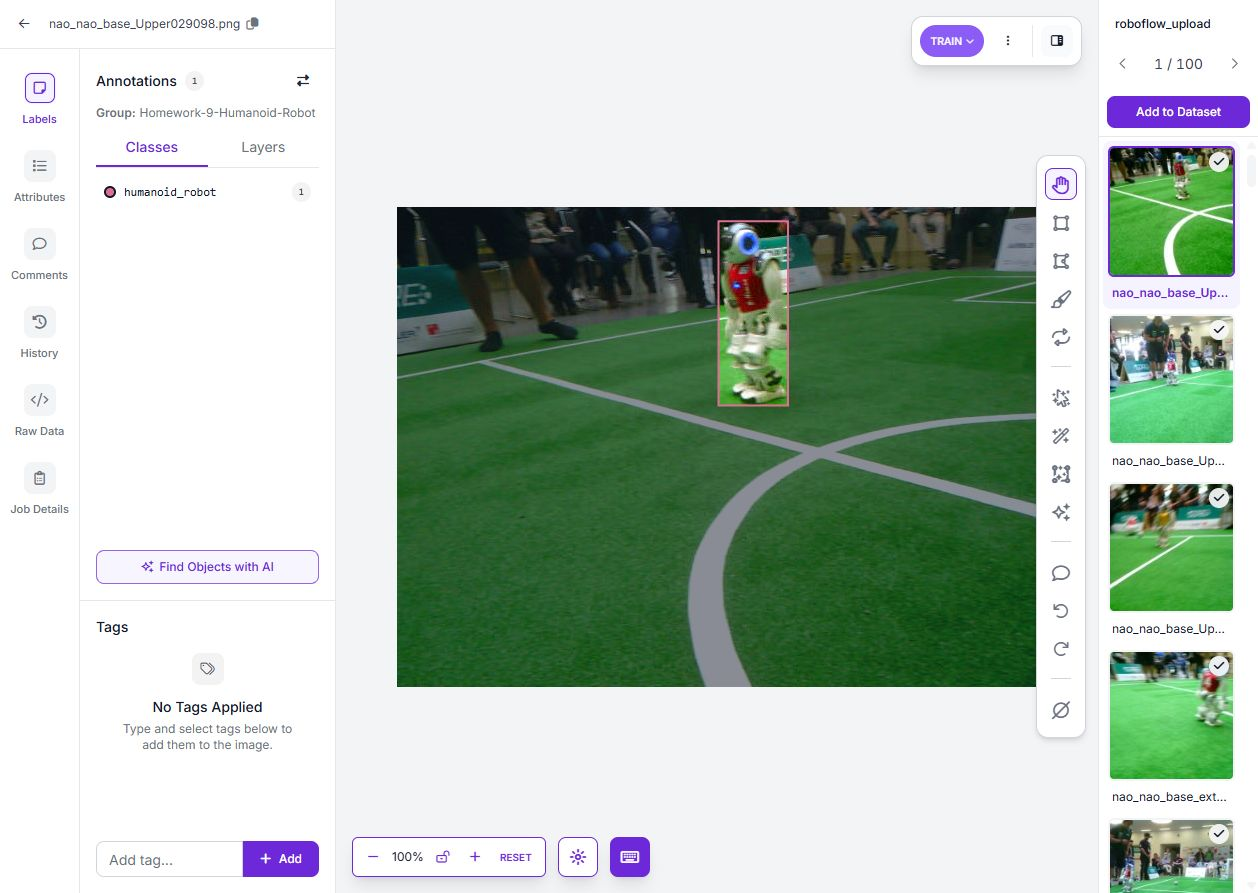

In [4]:
from IPython.display import Image as NotebookImage

display(NotebookImage(filename="roboflow_annotate.jpg", width=900))

На снимке из Annotate рамка охватывает одного робота NAO, а фон и зрители остались без рамок. В верхней части окна виден раздел train, слева — метка `humanoid_robot`.

,Сцен
split,
test,50
train,85
val,15


,Модель,mean_best_iou,precision_at_iou50,recall_at_iou50,f1_at_iou50,tp,fp,fn,ground_truth,photos,IoU без учёта класса,Ошибочные метки при IoU≥0.5
0,YOLOv8n · COCO,0.000,0.000,0.000,0.000,0,0,159,159,50,0.219,"{'motorcycle': 1, 'person': 29, 'dog': 1, 'bac..."
1,YOLOv8n · Roboflow,0.093,0.905,0.119,0.211,19,2,140,159,50,0.093,{}


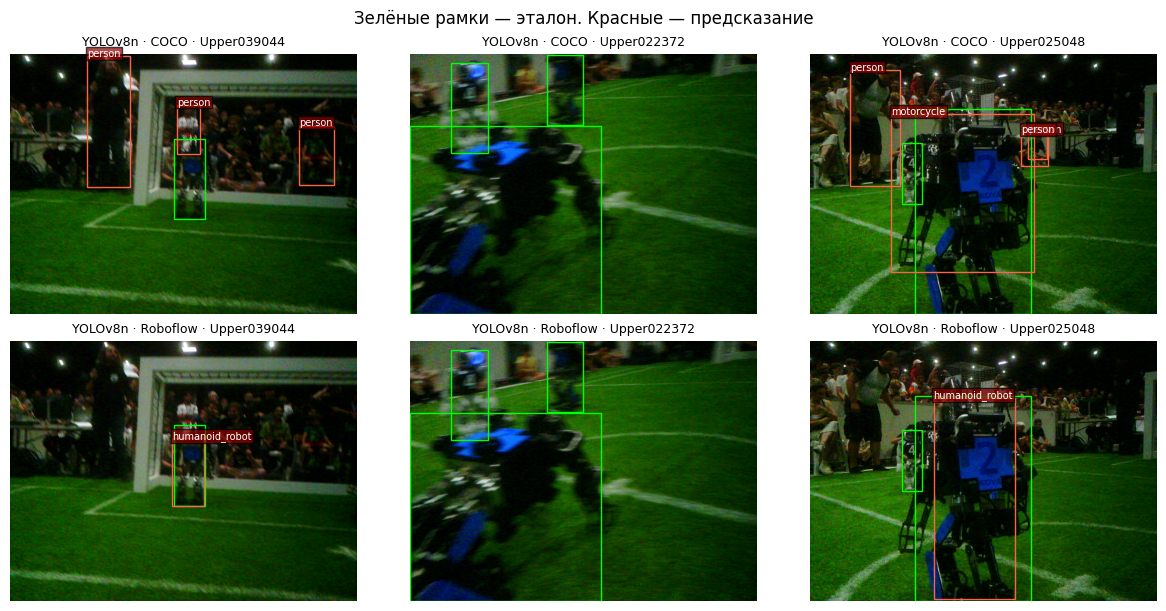

In [5]:
from box_metrics import intersection_over_union

scene_manifest = pd.DataFrame(load("robot_manifest.json"))
display(scene_manifest.groupby("split").size().rename("Сцен").to_frame())
yolo = {label: load(results / f"{name}.json") for label, name in [
    ("YOLOv8n · COCO", "yolo_pretrained"), ("YOLOv8n · Roboflow", "yolo_roboflow")
]}
display(pd.DataFrame([{"Модель": label, **run["class_aware"],
                       "IoU без учёта класса": run["any_class"]["mean_best_iou"],
                       "Ошибочные метки при IoU≥0.5": run["wrong_classes_overlapping_robots"]}
                      for label, run in yolo.items()]).round(3))
tuned = yolo["YOLOv8n · Roboflow"]["predictions"]
matched = [sum(any(intersection_over_union(a, b) >= 0.5 for b in row["boxes"])
               for a in row["truth"]) for row in tuned]
hit = next(i for i, (row, count) in enumerate(zip(tuned, matched)) if count == len(row["truth"]))
miss = next(i for i, row in enumerate(tuned) if not row["boxes"])
partial = next(i for i, (row, count) in enumerate(zip(tuned, matched)) if 0 < count < len(row["truth"]))
fig, axes = plt.subplots(len(yolo), 3, figsize=(12, 3 * len(yolo)), squeeze=False, constrained_layout=True)
for axes_row, (label, run) in zip(axes, yolo.items()):
    for axis, index in zip(axes_row, [hit, miss, partial]):
        row = run["predictions"][index]
        show_boxes(axis, row, title=f"{label} · {Path(row['scene']).stem[-11:]}")
fig.suptitle("Зелёные рамки — эталон. Красные — предсказание")
plt.show()

COCO-модель дала 32 совпадения рамок с роботами при IoU≥0.5, если игнорировать класс. Из предсказанных меток с таким перекрытием 29 — `person`, ещё три — `motorcycle`, `dog` и `backpack`. Класс `humanoid_robot` отсутствует в исходном словаре модели, поэтому правильных обнаружений именно этого класса было ноль.

На первом снимке дообученная модель локализовала единственного робота при IoU≥0.5. На втором обе модели пропустили трёх роботов. На третьем дообученная модель нашла одного из двух. Исходная модель на этом снимке выдала рамки с метками `person` и `motorcycle`.

На независимом тесте дообученная модель правильно обнаружила 19 из 159 роботов. При IoU≥0.5 Precision составила 0.905, Recall — 0.119, F1 — 0.211. Средний лучший IoU с учётом пропусков равен 0.093. Модель выводит мало ошибочных рамок при выбранном пороге уверенности, но пропускает 140 объектов. На validation у выбранных весов mAP50 равен 0.913. Эти метрики рассчитаны на разных выборках и по разным правилам. Тест снят на другом матче, где встречаются другие модели роботов и тёмные кадры. Результат на validation даёт ограниченное представление о качестве работы на таких сценах.

## Дополнительные шаги. SSDlite и Faster R-CNN

Выбран публичный Penn–Fudan с пешеходами. Берём 150 сцен из ДЗ‑8 с исходными рамками, полученными по маскам. Разбиение 100/25/25 является общим для обеих моделей. Используем SSDlite320 с MobileNetV3 и Faster R-CNN MobileNetV3-FPN 320 с весами COCO. SSD предсказывает классы и рамки за один проход. Faster R-CNN сначала предлагает области, затем уточняет классы и рамки. Обе модели дообучены 3 эпохи на CPU с замороженным backbone, лучшая эпоха выбрана по F1 при IoU≥0.5 на validation. На test оставляем предсказания класса person с confidence ≥ 0.35.

IoU — площадь пересечения двух рамок, делённая на площадь их объединения. Средний лучший IoU считается по всем эталонным объектам, включая пропуски. У каждого эталона выбирается лучшее перекрытие. Precision и Recall рассчитаны при IoU≥0.5 с однозначным сопоставлением рамок. Лишние рамки учитываются в Precision.

Повторный запуск: `python pedestrian_detection.py ssdlite` и `python pedestrian_detection.py faster_rcnn`.

,Модель,Лучшая эпоха,mean_best_iou,precision_at_iou50,recall_at_iou50,f1_at_iou50,tp,fp,fn,ground_truth,photos
0,SSDlite320,2,0.796,0.952,0.908,0.929,59,3,6,65,25
1,Faster R-CNN,1,0.829,0.924,0.938,0.931,61,5,4,65,25


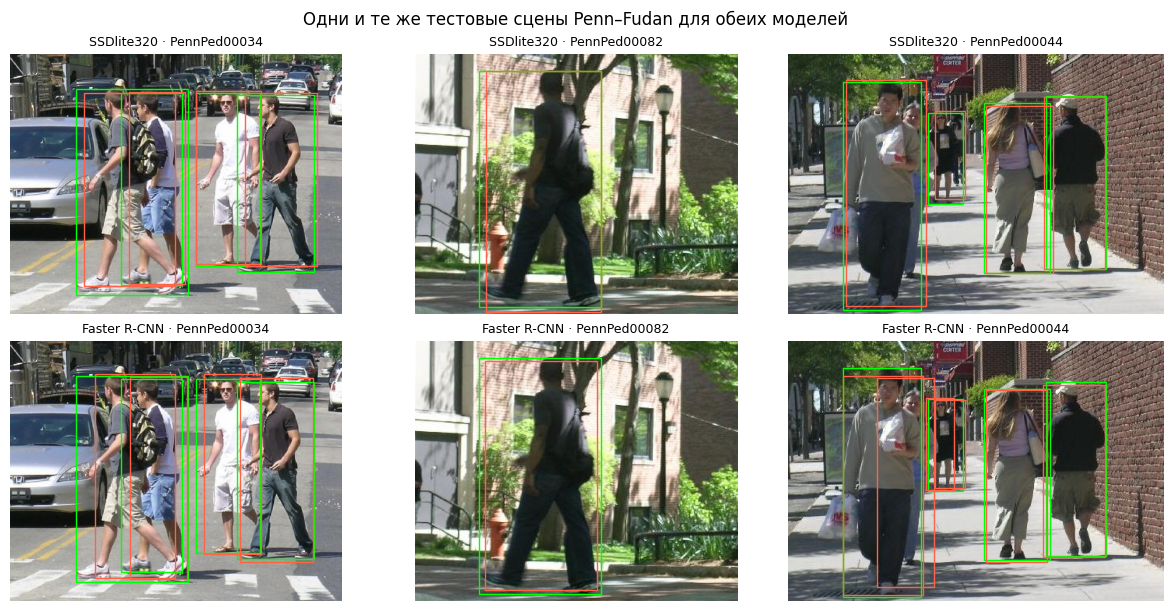

In [6]:
detectors = {label: load(results / f"{name}.json") for label, name in [
    ("SSDlite320", "ssdlite"), ("Faster R-CNN", "faster_rcnn")
] if (results / f"{name}.json").exists()}
assert len({tuple(run["split"]["test"]) for run in detectors.values()}) == 1
display(pd.DataFrame([{"Модель": label, "Лучшая эпоха": run["best_epoch"], **run["test"]}
                      for label, run in detectors.items()]).round(3))
fig, axes = plt.subplots(len(detectors), 3, figsize=(12, 3 * len(detectors)), squeeze=False, constrained_layout=True)
for axes_row, (label, run) in zip(axes, detectors.items()):
    for axis, index in zip(axes_row, [0, 8, 16]):
        row = run["predictions"][index]
        show_boxes(axis, row, Path("../homework8"), title=f"{label} · {Path(row['scene']).stem}")
fig.suptitle("Одни и те же тестовые сцены Penn–Fudan для обеих моделей")
plt.show()

На 25 одинаковых тестовых сценах с 65 эталонными пешеходами средний лучший IoU составил 0.796 у SSDlite и 0.829 у Faster R-CNN. Faster R-CNN правильно сопоставила 61 рамку против 59 у SSDlite и пропустила на двух человек меньше. У SSDlite меньше ложных рамок, три против пяти, поэтому Precision выше (0.952 против 0.924). Faster R-CNN лидирует по среднему лучшему IoU, а F1 при IoU≥0.5 у моделей близок (0.929 и 0.931). На примерах зелёные эталонные рамки можно напрямую сравнить с красными предсказаниями обеих сетей.

## Источники

[YOLOv8](https://docs.ultralytics.com/models/yolov8/), [Roboflow Annotate](https://docs.roboflow.com/datasets/annotate/annotate/annotation-tools), [кадры и рамки B-Human](https://b-human.informatik.uni-bremen.de/public/datasets/robots/), [Penn–Fudan](https://www.cis.upenn.edu/~jshi/ped_html/), [VGG](https://docs.pytorch.org/vision/stable/models/vgg.html), [SSDlite320](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.detection.ssdlite320_mobilenet_v3_large.html) и [Faster R-CNN 320](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.detection.fasterrcnn_mobilenet_v3_large_320_fpn.html).